In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py
import re

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'
with h5py.File(filename, 'r') as f:
    low_cat_matrix = f['data/lowest_tier_category_matrix_raw'][:]
    high_cat_matrix = f['data/highest_tier_category_matrix_raw'][:] 
    gene_names = f['meta/genes/all_gene_names'][:]
    gene_description = f['meta/genes/gene_description'][:]
    category_names = f['meta/biosamples/category'][:]

category_names = [x.decode('UTF-8') for x in category_names]
gene_names = [x.decode('UTF-8') for x in gene_names]
gene_description = [x.decode('UTF-8') for x in gene_description]

category_list  = ["Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle","HUVEC", 
    "Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
    "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF",
    "HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
    "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
    "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
    "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus","Granulocyte", "Neutrophil", "Blymphocyte", 
    "Plasma Cell", "Plasmacytoid Dendritic Cell", 
    "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
    "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
    "Thymocyte", "Spleen",
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC","Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
    "Vascular Smooth Muscle", "LHCNM2","Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
    "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
    "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron","Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
    "Trachea","Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
    "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
    "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]

category_dict  = {
    "Cardiovascular System" : ["Heart", "Atrium", "Cardiac Muscle Fiber", 
                               "Pericardium", "Valve", "Ventricle",
                               "HUVEC"], 
    
    "Connective Tissue" : ["Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
                           "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF"],

    "Digestive System": ["HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
                         "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
                         "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
                         "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus"],
    
    "Immune System" : ["Granulocyte", "Neutrophil", "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", 
                       "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
                       "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
                       "Thymocyte", "Spleen"],
    
    "Integumentary System" : ["Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                              "A431", "HACAT", "HNSCC"], 
    
    "Muscular System" : ["Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
                         "Vascular Smooth Muscle", "LHCNM2"], 
    
    "Nervous System" : ["Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
                        "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
                        "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron"], 
    
    "Respiratory System" : ["Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
                            "Trachea"], 
    
    "Urogenital System" : ["Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
                           "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
                           "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]
}

In [ ]:
with h5py.File(filename, 'r') as f:
    matrix = f['data/raw_matrix'][:]
    #matrix2 = f['data/_matrix'][:]
    
    data_group = f['data']
        # Get the keys within the data group
    keys = list(data_group.keys())

    # Print the keys
    for key in keys:
        print(key)


In [11]:
matrix.shape

(57447, 192601)

In [13]:
low_cat_matrix[0][0:3]

array([219.33996383, 110.86      ,          nan])

In [15]:
high_cat_matrix[0][0:3]

array([ 94.79237845,  99.22251054, 113.55603686])

In [17]:
from IPython.display import display

df = pd.DataFrame(low_cat_matrix, index=gene_names)
df.columns = category_list
#display(df)

---
# Calculations

In [19]:

# Compute row-wise averages while skipping NaN values
row_averages = np.nanmean(low_cat_matrix, axis=1)

# Create new matrix where each value is divided by row average
low_cat_oe_matrix = np.divide(low_cat_matrix, row_averages[:, np.newaxis], 
                       out=np.zeros_like(low_cat_matrix), where=row_averages[:, np.newaxis]!=0)

print("Low Cat matrix shape:")
print(low_cat_matrix.shape)
print(low_cat_matrix[0][:5])
print()
print("Average:", row_averages[0])
print()
print("Low Cat OE matrix shape:")
print(low_cat_oe_matrix.shape)
print(low_cat_oe_matrix[0][:5])

Low Cat matrix shape:
(57447, 127)
[219.33996383 110.86                nan 345.125      138.42222222]

Average: 239.42489560022628

Low Cat OE matrix shape:
(57447, 127)
[0.91611177 0.4630262         nan 1.44147499 0.57814465]


In [21]:
low_cat_log2_oe_matrix = np.log2(low_cat_oe_matrix)

/tmp/ipykernel_26921/140735222.py:1: RuntimeWarning: divide by zero encountered in log2
  low_cat_log2_oe_matrix = np.log2(low_cat_oe_matrix)


In [ ]:
from IPython.display import display

df = pd.DataFrame(low_cat_log2_oe_matrix, index=gene_names)
df.columns = category_list
display(df)

---
# Save OE Matrix

In [23]:
# Open the HDF5 file in read/write mode
with h5py.File(filename, "a") as file:
    # Access the "data" group
    group = file["data"]
    
    # Create and save the dataset
    group.create_dataset("low_tier_oe_matrix_raw", data=low_cat_oe_matrix)
    group.create_dataset("low_tier_log2oe_matrix_raw", data=low_cat_log2_oe_matrix)
    


ValueError: Unable to create dataset (name already exists)

---
# Results

In [ ]:
high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)

# Open the HDF5 file in read/write mode
with h5py.File(filename, "a") as file:
    # Access the "data" group
    group = file["data"]
    
    # Create and save the dataset
    group.create_dataset("high_tier_oe_matrix_raw", data=high_cat_oe_matrix)
    group.create_dataset("high_tier_log2oe_matrix_raw", data=high_cat_log2_oe_matrix)
    


In [47]:
df = pd.DataFrame(low_cat_matrix, index=gene_names)
df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 genes in Column "{} - Raw":'.format(col))
    for gene in top_10.index:
        index = gene_names.index(gene)
        value = top_10[gene]
        description = gene_description[index]
        print('{} ({}) [{}]'.format(gene,format(value, ".3f"), description))
    print()



Top 10 genes in Column "Heart - Raw":
TTN (647856.631) [titin]
MALAT1 (511859.195) [metastasis associated lung adenocarcinoma transcript 1]
RN7SL2 (260951.490) [RNA component of signal recognition particle 7SL2]
MYH7 (255844.973) [myosin heavy chain 7]
RN7SL1 (145478.508) [RNA component of signal recognition particle 7SL1]
FN1 (135605.459) [fibronectin 1]
EEF1A1 (102114.568) [eukaryotic translation elongation factor 1 alpha 1]
DES (92970.266) [desmin]
TPM1 (87134.278) [tropomyosin 1]
ACTC1 (84454.626) [actin alpha cardiac muscle 1]

Top 10 genes in Column "Atrium - Raw":
TTN (2524683.580) [titin]
RN7SL2 (1031456.580) [RNA component of signal recognition particle 7SL2]
RN7SL1 (664775.540) [RNA component of signal recognition particle 7SL1]
MYH7 (529564.360) [myosin heavy chain 7]
HBB (411835.960) [hemoglobin subunit beta]
DES (197321.080) [desmin]
HBA1 (178785.180) [hemoglobin subunit alpha 1]
HBG2 (152931.900) [hemoglobin subunit gamma 2]
TPM1 (139918.160) [tropomyosin 1]
MALAT1 (13575

Top 10 genes in Column "Hepatic Stellate Cell - Raw":
EEF1A1 (121512.564) [eukaryotic translation elongation factor 1 alpha 1]
LYZ (48985.257) [lysozyme]
ACTB (36307.168) [actin beta]
TPT1 (29258.455) [tumor protein, translationally-controlled 1]
MPO (27831.604) [myeloperoxidase]
RPL3 (27782.693) [ribosomal protein L3]
B2M (26325.347) [beta-2-microglobulin]
S100A9 (26185.396) [S100 calcium binding protein A9]
GAPDH (22340.347) [glyceraldehyde-3-phosphate dehydrogenase]
RPS6 (21622.059) [ribosomal protein S6]

Top 10 genes in Column "Hepatocyte - Raw":
HBB (335385.502) [hemoglobin subunit beta]
EEF1A1 (259152.589) [eukaryotic translation elongation factor 1 alpha 1]
FN1 (167808.726) [fibronectin 1]
HBA2 (125392.001) [hemoglobin subunit alpha 2]
RN7SL1 (116761.856) [RNA component of signal recognition particle 7SL1]
RN7SL2 (112754.158) [RNA component of signal recognition particle 7SL2]
ACTB (104905.943) [actin beta]
FTL (95574.659) [ferritin light chain]
HBA1 (87834.357) [hemoglobin sub

Top 10 genes in Column "U937 - Raw":
ALB (295013.124) [albumin]
PCSK5 (145111.034) [proprotein convertase subtilisin/kexin type 5]
MTND1P23 (134746.769) [MT-ND1 pseudogene 23]
SERPINA1 (73044.115) [serpin family A member 1]
APOB (53634.953) [apolipoprotein B]
IGKC (40231.427) [immunoglobulin kappa constant]
FTL (39828.620) [ferritin light chain]
ACTB (29970.205) [actin beta]
MALAT1 (29765.380) [metastasis associated lung adenocarcinoma transcript 1]
ALDOB (28967.235) [aldolase, fructose-bisphosphate B]

Top 10 genes in Column "JEG3 - Raw":
PCSK5 (78129.591) [proprotein convertase subtilisin/kexin type 5]
MTND1P23 (75910.136) [MT-ND1 pseudogene 23]
MALAT1 (39853.091) [metastasis associated lung adenocarcinoma transcript 1]
IGKC (16536.773) [immunoglobulin kappa constant]
OAS3 (15694.045) [2'-5'-oligoadenylate synthetase 3]
RGPD4-AS1 (14957.500) [RGPD4 antisense RNA 1 (head to head)]
ENSG00000224058 (14745.364) [novel pseudogene]
TEDC2-AS1 (13942.273) [TEDC2 antisense RNA 1]
RPL41 (13822

Top 10 genes in Column "Hypothalamus - Raw":
GCG (243041.739) [glucagon]
TTR (74075.304) [transthyretin]
MALAT1 (49977.783) [metastasis associated lung adenocarcinoma transcript 1]
B2M (8277.652) [beta-2-microglobulin]
FTL (7295.783) [ferritin light chain]
PPP1CB (6413.870) [protein phosphatase 1 catalytic subunit beta]
CHGB (5854.217) [chromogranin B]
SCG5 (5750.217) [secretogranin V]
EEF1A1 (4855.870) [eukaryotic translation elongation factor 1 alpha 1]
ENSG00000203396 (4121.087) [WDR45-like (WDR45L) pseudogene]

Top 10 genes in Column "Medula - Raw":
A1BG (nan) [alpha-1-B glycoprotein]
A1BG-AS1 (nan) [A1BG antisense RNA 1]
A1CF (nan) [APOBEC1 complementation factor]
A2M (nan) [alpha-2-macroglobulin]
A2M-AS1 (nan) [A2M antisense RNA 1]
A2ML1 (nan) [alpha-2-macroglobulin like 1]
A2ML1-AS1 (nan) [A2ML1 antisense RNA 1]
A2ML1-AS2 (nan) [A2ML1 antisense RNA 2]
A2MP1 (nan) [alpha-2-macroglobulin pseudogene 1]
A3GALT2 (nan) [alpha 1,3-galactosyltransferase 2]

Top 10 genes in Column "Midbr

Top 10 genes in Column "T47D - Raw":
ENSG00000280614 (22243.013) [novel transcript, similar to YY1 associated myogenesis RNA 1 YAM1]
ENSG00000280800 (22243.013) [novel transcript, similar to YY1 associated myogenesis RNA 1 YAM1]
ENSG00000281181 (22243.013) [novel transcript, similar to YY1 associated myogenesis RNA 1 YAM1]
FTL (20243.720) [ferritin light chain]
EEF1A1 (10015.962) [eukaryotic translation elongation factor 1 alpha 1]
ENSG00000225840 (9740.296) [RNA, 18S ribosomal pseudogene]
FTH1 (9544.805) [ferritin heavy chain 1]
ACTB (7406.824) [actin beta]
CD74 (5868.783) [CD74 molecule]
CTSB (5721.272) [cathepsin B]

Top 10 genes in Column "HELA - Raw":
EEF1A1 (131666.240) [eukaryotic translation elongation factor 1 alpha 1]
FN1 (114269.389) [fibronectin 1]
RN7SL2 (85784.115) [RNA component of signal recognition particle 7SL2]
RN7SL1 (85389.581) [RNA component of signal recognition particle 7SL1]
MALAT1 (81222.225) [metastasis associated lung adenocarcinoma transcript 1]
COL1A1 (603

In [39]:
df = pd.DataFrame(low_cat_oe_matrix, index=gene_names)
df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Heart":
RNU1-61P           60.186601
ENSG00000274866    56.043351
ENSG00000239628    51.691509
ENSG00000237324    45.190871
ENSG00000253805    44.802203
ENSG00000286639    44.258963
ENSG00000252868    43.734715
MYH1               41.970089
RNA5SP162          41.964429
GJD2-DT            41.900047
Name: Heart, dtype: float64

Gene descriptions for Column "Heart":
RNA, U1 small nuclear 61, pseudogene
None
novel transcript
novel transcript
novel transcript
novel transcript
None
myosin heavy chain 1
RNA, 5S ribosomal pseudogene 162
GJD2 divergent transcript

Top 10 values in Column "Atrium":
MIR7151            96.599024
MIR4463            95.961860
MIR4780            95.349347
RNU6-699P          92.684612
MIR4493            88.980072
ENSG00000201666    86.250184
ENSG00000230112    84.542970
RNA5SP501          84.198270
RNU1-34P           83.329044
RNU7-25P           82.983795
Name: Atrium, dtype: float64

Gene descriptions for Column "Atrium":
microRNA 7151
microRN

Top 10 values in Column "Liver":
RNU1-64P           67.536837
ENSG00000288712    61.442909
CYP2C56P           56.533748
LINC01507          56.029156
ENSG00000282973    54.400568
MIR146A            53.583692
PRSS3P3            52.863037
ENSG00000229509    50.594113
ENSG00000260564    48.501507
ENSG00000244193    48.490280
Name: Liver, dtype: float64

Gene descriptions for Column "Liver":
RNA, U1 small nuclear 64, pseudogene
novel protein
cytochrome P450 family 2 subfamily C member 56, pseudogene
long intergenic non-protein coding RNA 1507
double homeobox protein (DUX) pseudogene
microRNA 146a
PRSS3 pseudogene 3
RAP1, GTP-GDP dissociation stimulator 1 (RAP1GDS1) pseudogene
novel transcript
four and a half LIM domains 1 (FHL1) pseudogene

Top 10 values in Column "Hepatic Stellate Cell":
RNA5SP497          72.578211
ENSG00000269993    68.925647
ENSG00000267133    63.563187
ENSG00000263720    59.395672
ENSG00000252404    57.037855
LPGAT1-AS1         56.212830
RNU6-1219P         55.891690
PH

Top 10 values in Column "Alveolar":
CDK9               77.937615
RN7SL326P          72.036900
IGLV5-37           71.373328
RNU2-9P            58.286443
ENSG00000286719    53.505289
RNU6-1211P         51.274284
MTND3P25           48.525895
SNX3P1Y            48.057602
ENSG00000238291    46.466974
GNAT3              42.158466
Name: Alveolar, dtype: float64

Gene descriptions for Column "Alveolar":
cyclin dependent kinase 9
RNA, 7SL, cytoplasmic 326, pseudogene
immunoglobulin lambda variable 5-37
RNA, U2 small nuclear 9, pseudogene
novel transcript
RNA, U6 small nuclear 1211, pseudogene
MT-ND3 pseudogene 25
sorting nexin 3 pseudogene 1 Y-linked
novel transcript
G protein subunit alpha transducin 3

Top 10 values in Column "Dendritic":
RPS20P21           100.588944
HIGD1AP14           90.049185
ENSG00000275654     87.772039
NACA2               85.181735
TNRC18P3            72.382135
SUCLG2P2            70.554611
HMGB3P6             69.393355
ENSG00000288706     66.435309
ERP29P1           

Top 10 values in Column "Vascular Smooth Muscle":
ABHD17AP9          73.638719
WBP1LP4            68.315311
SNX18P24           58.528556
ENSG00000267072    52.215786
ZFYVE9P1           52.191064
ENSG00000250194    50.716585
DUXAP3             45.608198
AK6P1              44.688748
NBEAP4             42.101494
NF1P10             40.154354
Name: Vascular Smooth Muscle, dtype: float64

Gene descriptions for Column "Vascular Smooth Muscle":
ABHD17A pseudogene 9
WBP1L pseudogene 4
sorting nexin 18 pseudogene 24
novel transcript
zinc finger FYVE-type containing 9 pseudogene 1
novel pseudogene
double homeobox A pseudogene 3
adenylate kinase 6 pseudogene 1
neurobeachin pseudogene 4
neurofibromin 1 pseudogene 10

Top 10 values in Column "LHCNM2":
USP12PY            82.314951
AK3P2              65.928970
KRT18P51           64.100667
ARL5AP4            60.347927
MIR6733            55.675258
ENSG00000233565    47.821668
ENSG00000261310    44.329081
ENSG00000257191    44.140147
RN7SL41P           4

Top 10 values in Column "MRC5":
LINC01074          99.726436
LINC00459          99.610162
IGLV1-40           93.007795
ELOCP5             92.066740
ENSG00000259743    87.886573
IGHV4-39           82.879770
ENSG00000250213    81.410358
RNU6-1135P         81.137868
RNA5SP186          80.866755
IGLJ2              77.295790
Name: MRC5, dtype: float64

Gene descriptions for Column "MRC5":
long intergenic non-protein coding RNA 1074
long intergenic non-protein coding RNA 459
immunoglobulin lambda variable 1-40
elongin C pseudogene 5
phosphodiesterase 8B (PDE8B) pseudogene
immunoglobulin heavy variable 4-39
COX17 cytochrome c oxidase assembly homolog (S. cerevisiae) (COX17) pseudogene
RNA, U6 small nuclear 1135, pseudogene
RNA, 5S ribosomal pseudogene 186
immunoglobulin lambda joining 2

Top 10 values in Column "NCIH460":
ENSG00000231353    100.370569
MIR3681             99.137769
ENSG00000230803     98.673043
SNORD115-47         94.161606
RNU6-717P           93.176091
RNU6-1110P          91.

Top 10 values in Column "Granulosa":
RN7SL87P           103.729017
RNU4-25P           103.136229
RN7SL724P           99.907157
RN7SL229P           94.129982
ENSG00000257813     87.052196
RN7SL597P           84.474642
RN7SL685P           75.546824
ENSG00000213655     72.739610
RN7SL617P           70.042825
RN7SKP148           69.779230
Name: Granulosa, dtype: float64

Gene descriptions for Column "Granulosa":
RNA, 7SL, cytoplasmic 87, pseudogene
RNA, U4 small nuclear 25, pseudogene
RNA, 7SL, cytoplasmic 724, pseudogene
RNA, 7SL, cytoplasmic 229, pseudogene
protein-kinase, interferon-inducible double stranded RNA dependent inhibitor, repressor of (P58 repressor) (PRKRIR) pseudogene
RNA, 7SL, cytoplasmic 597, pseudogene
RNA, 7SL, cytoplasmic 685, pseudogene
SMT3 suppressor of mif two 3 homolog 1 (S. cerevisiae) (SUMO1) pseudogene
RNA, 7SL, cytoplasmic 617, pseudogene
RN7SK pseudogene 148

Top 10 values in Column "Oocyte":
ENSG00000231495    53.432209
ENSG00000241257    40.406867
CER1     

In [40]:
df = pd.DataFrame(low_cat_log2_oe_matrix, index=gene_names)
df.columns = category_list

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 genes in Column "{} - Log O/E Raw":'.format(col))
    for gene in top_10.index:
        index = gene_names.index(gene)
        value = top_10[gene]
        description = gene_description[index]
        print('{} ({}) [{}]'.format(gene,format(value, ".3f"), description))
    print()


Top 10 genes in Column "Heart - Log O/E Raw":
RNU1-61P (5.911) [RNA, U1 small nuclear 61, pseudogene]
ENSG00000274866 (5.808) [None]
ENSG00000239628 (5.692) [novel transcript]
ENSG00000237324 (5.498) [novel transcript]
ENSG00000253805 (5.485) [novel transcript]
ENSG00000286639 (5.468) [novel transcript]
ENSG00000252868 (5.451) [None]
MYH1 (5.391) [myosin heavy chain 1]
RNA5SP162 (5.391) [RNA, 5S ribosomal pseudogene 162]
GJD2-DT (5.389) [GJD2 divergent transcript]

Top 10 genes in Column "Atrium - Log O/E Raw":
MIR7151 (6.594) [microRNA 7151]
MIR4463 (6.584) [microRNA 4463]
MIR4780 (6.575) [microRNA 4780]
RNU6-699P (6.534) [RNA, U6 small nuclear 699, pseudogene]
MIR4493 (6.475) [microRNA 4493]
ENSG00000201666 (6.430) [None]
ENSG00000230112 (6.402) [pseudogene similar to part of MTCO3 (COIII)(cytochrome c oxidase III)]
RNA5SP501 (6.396) [RNA, 5S ribosomal pseudogene 501]
RNU1-34P (6.381) [RNA, U1 small nuclear 34, pseudogene]
RNU7-25P (6.375) [RNA, U7 small nuclear 25 pseudogene]

Top 1

Top 10 genes in Column "HCT116 - Log O/E Raw":
TSPY7P (6.666) [testis specific protein Y-linked 7, pseudogene]
IGHV3OR16-6 (6.618) [immunoglobulin heavy variable 3/OR16-6 (pseudogene)]
SNORD18B (6.465) [small nucleolar RNA, C/D box 18B]
MIR124-1 (6.362) [microRNA 124-1]
MIR1244-1 (6.232) [microRNA 1244-1]
MIR1244-2 (6.232) [microRNA 1244-2]
MIR1244-3 (6.232) [microRNA 1244-3]
MIR1244-4 (6.232) [microRNA 1244-4]
IGHV1OR21-1 (6.179) [immunoglobulin heavy variable 1/OR21-1 (non-functional)]
IGLV5-52 (6.162) [immunoglobulin lambda variable 5-52]

Top 10 genes in Column "HT29 - Log O/E Raw":
MIR451B (6.811) [microRNA 451b]
ENSG00000251095 (6.665) [novel transcript]
RPS5P8 (6.589) [RPS5 pseudogene 8]
ECRG4 (6.588) [ECRG4 augurin precursor]
RPS27AP15 (6.574) [RPS27A pseudogene 15]
RPS7P6 (6.556) [ribosomal protein S7 pseudogene 6]
MMP3 (6.532) [matrix metallopeptidase 3]
MIR5681B (6.496) [microRNA 5681b]
ENSG00000236571 (6.494) [ribosomal protein S13 (RPS13) pseudogene]
MSMP (6.454) [microsem

Top 10 genes in Column "GSM2679484 - Log O/E Raw":
ENSG00000239255 (-inf) [pseudogene similar to part of guanine nucleotide binding protein (G protein), beta polypeptide 1GNB1]
ENSG00000255972 (-inf) [chemokine (C-C motif) receptor-like 2 (CCRL2) pseudogene]
ENSG00000266416 (-inf) [lectin, galactoside-binding, soluble, 9 (LGALS9) pseudogene]
ENSG00000271041 (-inf) [coiled-coil domain containing 58 (CCDC58) pseudogene]
ENSG00000271154 (-inf) [coiled-coil domain containing 58 (CCDC58) pseudogene]
ENSG00000271544 (-inf) [myxovirus (influenza virus) resistance 1, interferon-inducible protein p78 (mouse) (MX1) pseudogene]
ENSG00000282732 (-inf) [novel pseudogene similar to part of zinc finger protein]
IGHD1-1 (-inf) [immunoglobulin heavy diversity 1-1]
IGHD1-14 (-inf) [immunoglobulin heavy diversity 1-14 (non-functional)]
IGHD1-20 (-inf) [immunoglobulin heavy diversity 1-20]

Top 10 genes in Column "JURKAT - Log O/E Raw":
PTH (6.766) [parathyroid hormone]
CEACAM20 (6.272) [CEA cell adhesion

Top 10 genes in Column "HNSCC - Log O/E Raw":
GH1 (6.849) [growth hormone 1]
ENSG00000253195 (6.294) [cytochrome P450, family 4, subfamily F, polypeptide 8 (CYP4F8) pseudogene]
LINC02211 (6.232) [long intergenic non-protein coding RNA 2211]
ALPI (6.170) [alkaline phosphatase, intestinal]
RPL14P1 (6.145) [ribosomal protein L14 pseudogene 1]
ENSG00000254145 (6.127) [chromosome 2 open reading frame 14 (C2orf14) pseudogene]
SNRPEP6 (6.061) [SNRPE pseudogene 6]
RNA5SP413 (6.043) [RNA, 5S ribosomal pseudogene 413]
CYP4F44P (6.022) [cytochrome P450 family 4 subfamily F member 44, pseudogene]
H3C14 (5.876) [H3 clustered histone 14]

Top 10 genes in Column "Skeletal Muscle - Log O/E Raw":
CSGALNACT2P2 (6.240) [CSGALNACT2 pseudogene 2]
HNRNPCL2 (5.913) [heterogeneous nuclear ribonucleoprotein C like 2]
ENSG00000253215 (5.783) [novel transcript]
UBE2NP1 (5.732) [ubiquitin conjugating enzyme E2 N pseudogene 1]
YTHDF2P1 (5.579) [YTH domain family member 2 pseudogene 1]
HNRNPCL4 (5.470) [heterogeneo

Top 10 genes in Column "Lung Epithelial - Log O/E Raw":
AMYP1 (6.644) [amylase alpha pseudogene 1]
ENSG00000285959 (6.274) [novel transcript]
AMY2A (6.208) [amylase alpha 2A]
CELA2A (6.186) [chymotrypsin like elastase 2A]
PNLIP (6.044) [pancreatic lipase]
CPB1 (6.004) [carboxypeptidase B1]
CELA2B (5.985) [chymotrypsin like elastase 2B]
PRSS1 (5.978) [serine protease 1]
CELA3B (5.948) [chymotrypsin like elastase 3B]
MIR3156-1 (5.940) [microRNA 3156-1]

Top 10 genes in Column "A549 - Log O/E Raw":
MIR20B (6.752) [microRNA 20b]
MIR7108 (6.335) [microRNA 7108]
MIR20A (6.266) [microRNA 20a]
MIR614 (6.253) [microRNA 614]
MIR18A (6.073) [microRNA 18a]
ENSG00000288615 (5.896) [novel transcript]
RNA5SP358 (5.888) [RNA, 5S ribosomal pseudogene 358]
MTCYBP23 (5.557) [MT-CYB pseudogene 23]
RNU1-136P (5.549) [RNA, U1 small nuclear 136, pseudogene]
MIR196B (5.538) [microRNA 196b]

Top 10 genes in Column "H1299 - Log O/E Raw":
SPATA8-AS1 (6.531) [SPATA8 antisense RNA 1 (head to head)]
MIR3130-1 (6.35

Top 10 genes in Column "LNCAP - Log O/E Raw":
SCYGR7 (6.533) [small cysteine and glycine repeat containing 7]
KRTAP2-1 (6.530) [keratin associated protein 2-1]
KRTAP2-4 (6.492) [keratin associated protein 2-4]
KRTAP4-6 (6.485) [keratin associated protein 4-6]
KRTAP9-9 (6.479) [keratin associated protein 9-9]
KRTAP9-2 (6.469) [keratin associated protein 9-2]
KRTAP9-4 (6.464) [keratin associated protein 9-4]
KRTAP4-5 (6.454) [keratin associated protein 4-5]
KRTAP4-3 (6.450) [keratin associated protein 4-3]
KRTAP1-3 (6.448) [keratin associated protein 1-3]

Top 10 genes in Column "PC3 - Log O/E Raw":
IGKV1OR2-3 (6.851) [immunoglobulin kappa variable 1/OR2-3 (pseudogene)]
IGKV2D-10 (6.850) [immunoglobulin kappa variable 2D-10 (pseudogene)]
IGKV1D-35 (6.849) [immunoglobulin kappa variable 1D-35 (pseudogene)]
IGKV1OR2-11 (6.847) [immunoglobulin kappa variable 1/OR2-11 (pseudogene)]
IGKV1OR2-9 (6.847) [immunoglobulin kappa variable 1/OR2-9 (pseudogene)]
IGKV1D-12 (6.816) [immunoglobulin kappa

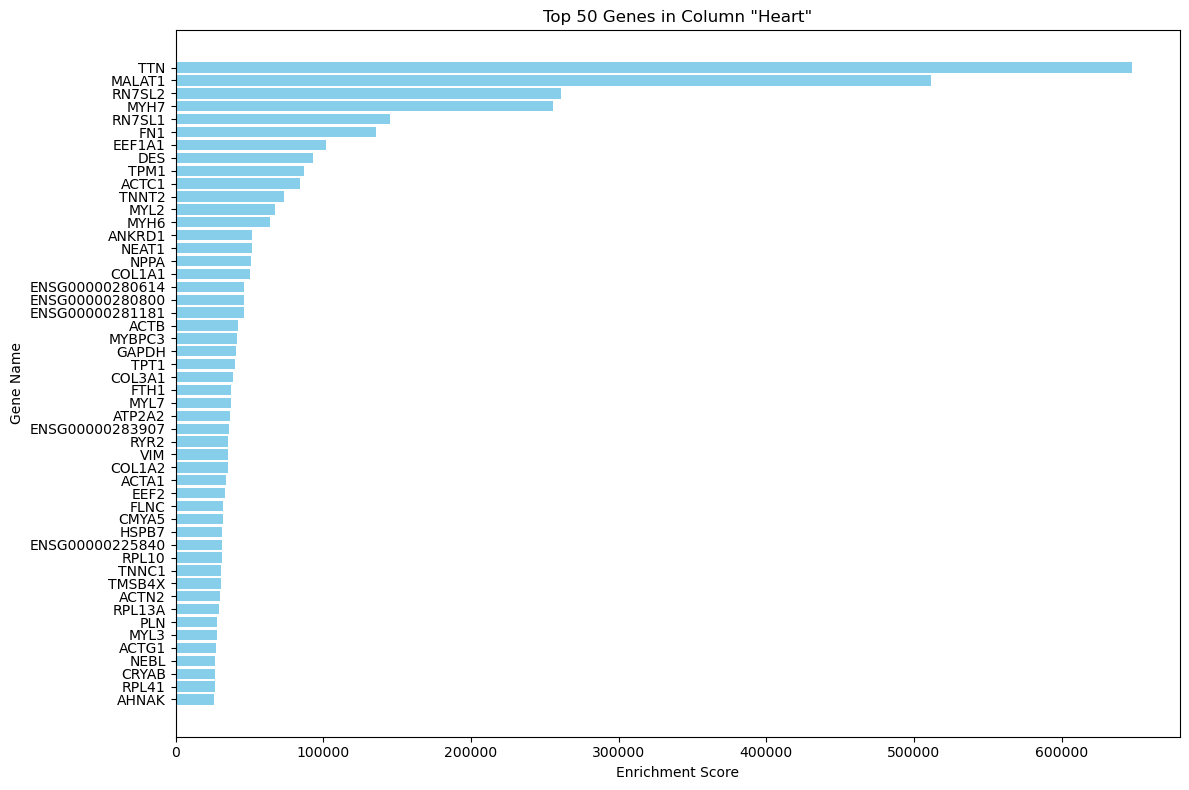

In [54]:
import matplotlib.pyplot as plt

# Select the column for the bar plot
column_name = "Heart"

# Get the top 50 scores for the selected column
top_50 = df[column_name].nlargest(50)
genes = [gene_names.index(gene) for gene in top_50.index]
scores = top_50.values

plt.figure(figsize=(12, 8))
plt.barh(range(len(genes)), scores, align='center', color='skyblue')
plt.yticks(range(len(genes)), [gene_names[gene] for gene in genes])
plt.xlabel('Enrichment Score')
plt.ylabel('Gene Name')
plt.title('Top 50 Genes in Column "{}"'.format(column_name))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

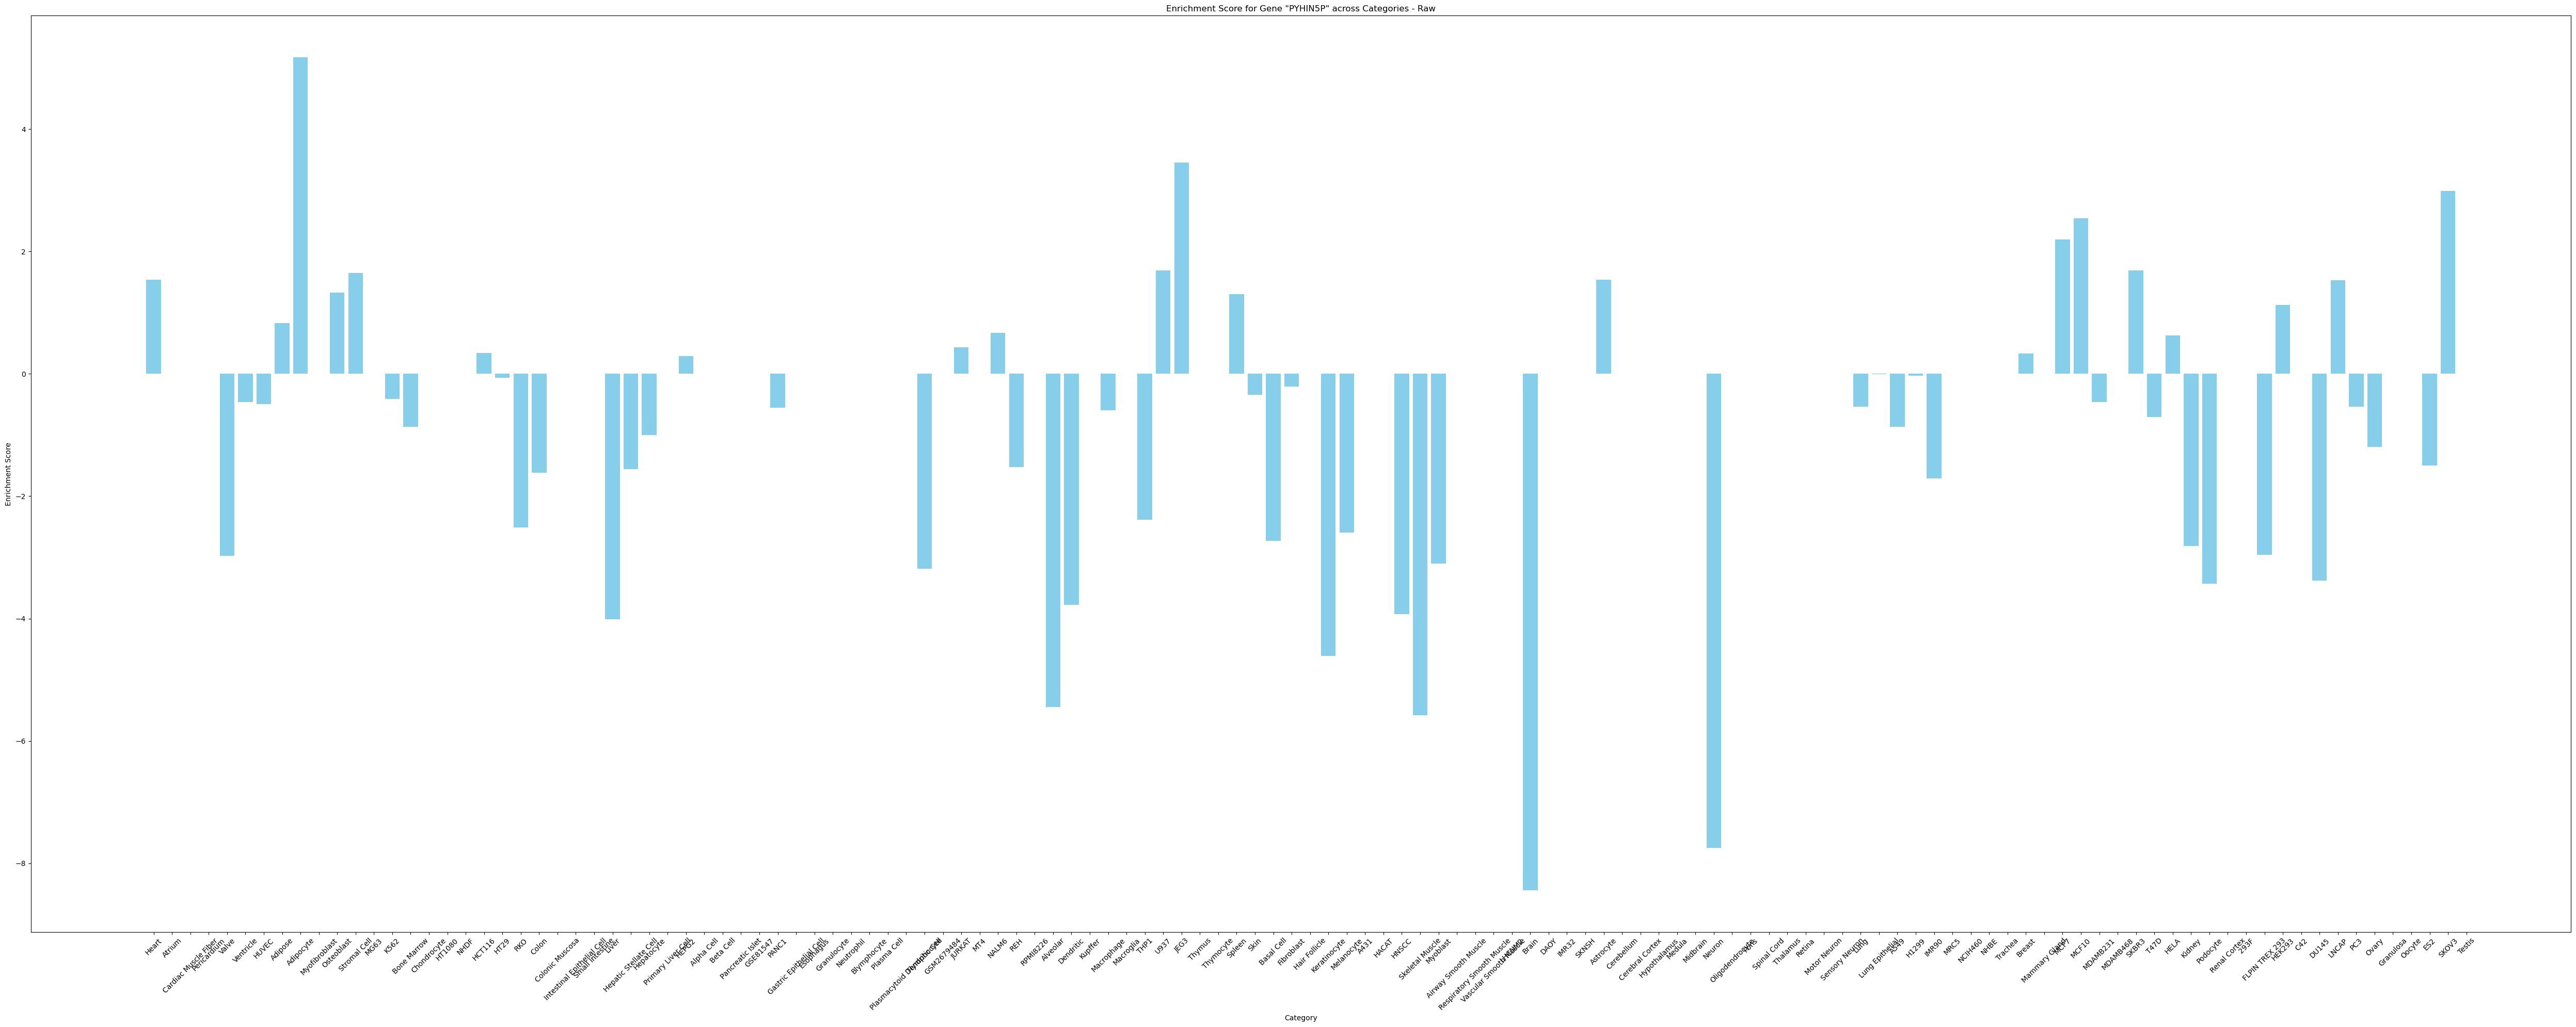

In [42]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'PYHIN5P'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(50, 20))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories - Raw'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


---
# System

In [25]:

# Compute row-wise averages while skipping NaN values
row_averages = np.nanmean(high_cat_matrix, axis=1)

# Create new matrix where each value is divided by row average
high_cat_oe_matrix = np.divide(high_cat_matrix, row_averages[:, np.newaxis], 
                       out=np.zeros_like(high_cat_matrix), where=row_averages[:, np.newaxis]!=0)

print("High Cat matrix shape:")
print(high_cat_matrix.shape)
print(high_cat_matrix[0][:5])
print()
print("Average:", row_averages[0])
print()
print("High Cat OE matrix shape:")
print(high_cat_oe_matrix.shape)
print(high_cat_oe_matrix[0][:5])

High Cat matrix shape:
(57447, 9)
[  94.79237845   99.22251054  113.55603686  937.5426037  1645.39369115]

Average: 378.969252455521

High Cat OE matrix shape:
(57447, 9)
[0.25013211 0.26182206 0.29964446 2.47392789 4.34176039]


In [26]:
# from IPython.display import display

# df = pd.DataFrame(high_cat_oe_matrix, index=gene_names)
# df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
# "Immune System", "Integumentary System", "Muscular System", "Nervous System", 
# "Respiratory System", "Urogenital System"]
# display(df)

---
# SAVE OE MATRIX

In [27]:
high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)

# Open the HDF5 file in read/write mode
with h5py.File(filename, "a") as file:
    # Access the "data" group
    group = file["data"]
    
    # Create and save the dataset
    group.create_dataset("high_tier_oe_matrix_raw", data=high_cat_oe_matrix)
    group.create_dataset("high_tier_log2oe_matrix_raw", data=high_cat_log2_oe_matrix)
    


/tmp/ipykernel_26921/1263805658.py:1: RuntimeWarning: divide by zero encountered in log2
  high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)


-
# View Dataset

In [56]:
# loop through each column and get the top 10 highest values and their indexes

df = pd.DataFrame(high_cat_matrix, index=gene_names)
df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print('Indexes for Column "{}":'.format(col))
    print(top_10.index)
    print()

Top 10 values in Column "Cardiovascular System":
TTN       363796.746386
MYH7      257208.147175
RN7SL2    166535.955760
EEF1A1    151958.555410
MALAT1    148783.611038
FN1       137134.439334
DES       118353.111695
RN7SL1    113326.609724
MYL2      112923.396408
ACTC1      93609.147175
Name: Cardiovascular System, dtype: float64
Indexes for Column "Cardiovascular System":
Index(['TTN', 'MYH7', 'RN7SL2', 'EEF1A1', 'MALAT1', 'FN1', 'DES', 'RN7SL1',
       'MYL2', 'ACTC1'],
      dtype='object')

Top 10 values in Column "Connective Tissue":
EEF1A1    178417.140988
FN1       143890.570440
RN7SL2    106031.128771
RN7SL1    105319.843659
SCD        84732.678452
COL1A1     76660.347389
HBG2       68364.906260
HBE1       62023.015029
COL1A2     61306.713050
FTL        59684.479403
Name: Connective Tissue, dtype: float64
Indexes for Column "Connective Tissue":
Index(['EEF1A1', 'FN1', 'RN7SL2', 'RN7SL1', 'SCD', 'COL1A1', 'HBG2', 'HBE1',
       'COL1A2', 'FTL'],
      dtype='object')

Top 10 va

In [16]:
df = pd.DataFrame(high_cat_oe_matrix, index=gene_names)
df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Cardiovascular System":
MYL2      8.967319
CSRP3     8.954127
TCAP      8.949683
LMOD2     8.947061
MYOZ2     8.944008
MYL3      8.940943
MYH7      8.938708
MYBPC3    8.931336
NRAP      8.925587
TNNT2     8.924723
Name: Cardiovascular System, dtype: float64

Gene descriptions for Column "Cardiovascular System":
myosin light chain 2
cysteine and glycine rich protein 3
titin-cap
leiomodin 2
myozenin 2
myosin light chain 3
myosin heavy chain 7
myosin binding protein C3
nebulin related anchoring protein
troponin T2, cardiac type

Top 10 values in Column "Connective Tissue":
MIR3926-2          9.000000
ENSG00000242327    8.996723
HBE1               8.679729
HBZP1              8.673883
LEP                8.662580
MIR3654            8.633528
ADIPOQ             8.627011
TRARG1             8.549229
LINCADL            8.524725
PLIN1              8.505909
Name: Connective Tissue, dtype: float64

Gene descriptions for Column "Connective Tissue":
microRNA 3926-2
ribosomal p

In [17]:
high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)
df = pd.DataFrame(high_cat_log2_oe_matrix, index=gene_names)
df.columns = ["Cardiovascular System",  "Connective Tissue", "Digestive System", 
"Immune System", "Integumentary System", "Muscular System", "Nervous System", 
"Respiratory System", "Urogenital System"]

for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 values in Column "{}":'.format(col))
    print(top_10)
    print()
    print('Gene descriptions for Column "{}":'.format(col))
    
    for gene in top_10.index:
        index = gene_names.index(gene)
        print(gene_description[index])
    print()


Top 10 values in Column "Cardiovascular System":
MYL2      3.164677
CSRP3     3.162553
TCAP      3.161837
LMOD2     3.161414
MYOZ2     3.160921
MYL3      3.160427
MYH7      3.160066
MYBPC3    3.158876
NRAP      3.157947
TNNT2     3.157807
Name: Cardiovascular System, dtype: float64

Gene descriptions for Column "Cardiovascular System":
myosin light chain 2
cysteine and glycine rich protein 3
titin-cap
leiomodin 2
myozenin 2
myosin light chain 3
myosin heavy chain 7
myosin binding protein C3
nebulin related anchoring protein
troponin T2, cardiac type

Top 10 values in Column "Connective Tissue":
MIR3926-2          3.169925
ENSG00000242327    3.169400
HBE1               3.117650
HBZP1              3.116678
LEP                3.114797
MIR3654            3.109950
ADIPOQ             3.108861
TRARG1             3.095794
LINCADL            3.091653
PLIN1              3.088465
Name: Connective Tissue, dtype: float64

Gene descriptions for Column "Connective Tissue":
microRNA 3926-2
ribosomal p

/tmp/ipykernel_48168/2203363747.py:1: RuntimeWarning: divide by zero encountered in log2
  high_cat_log2_oe_matrix = np.log2(high_cat_oe_matrix)


In [57]:
for col in df.columns:
    top_10 = df[col].nlargest(10)
    print('Top 10 genes in Column "{}":'.format(col))
    for gene in top_10.index:
        index = gene_names.index(gene)
        value = top_10[gene]
        description = gene_description[index]
        print('{} ({}) [{}]'.format(gene,format(value, ".3f"), description))
    print()

Top 10 genes in Column "Cardiovascular System":
TTN (363796.746) [titin]
MYH7 (257208.147) [myosin heavy chain 7]
RN7SL2 (166535.956) [RNA component of signal recognition particle 7SL2]
EEF1A1 (151958.555) [eukaryotic translation elongation factor 1 alpha 1]
MALAT1 (148783.611) [metastasis associated lung adenocarcinoma transcript 1]
FN1 (137134.439) [fibronectin 1]
DES (118353.112) [desmin]
RN7SL1 (113326.610) [RNA component of signal recognition particle 7SL1]
MYL2 (112923.396) [myosin light chain 2]
ACTC1 (93609.147) [actin alpha cardiac muscle 1]

Top 10 genes in Column "Connective Tissue":
EEF1A1 (178417.141) [eukaryotic translation elongation factor 1 alpha 1]
FN1 (143890.570) [fibronectin 1]
RN7SL2 (106031.129) [RNA component of signal recognition particle 7SL2]
RN7SL1 (105319.844) [RNA component of signal recognition particle 7SL1]
SCD (84732.678) [stearoyl-CoA desaturase]
COL1A1 (76660.347) [collagen type I alpha 1 chain]
HBG2 (68364.906) [hemoglobin subunit gamma 2]
HBE1 (620

---
# Analysis

In [ ]:
import matplotlib.pyplot as plt

# Select the column for the bar plot
column_name = "your_column_name"

# Get the top 100 scores for the selected column
top_100 = df[column_name].nlargest(100)
genes = [gene_names.index(gene) for gene in top_100.index]
scores = top_100.values

# Create subplots with one row and one column
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

# Plot the bar plot
ax.barh(range(len(genes)), scores, align='center', color='skyblue')
ax.set_yticks(range(len(genes)))
ax.set_yticklabels([gene_description[gene] for gene in genes])
ax.set_xlabel('Enrichment Score')
ax.set_ylabel('Gene Description')
ax.set_title('Top 100 Genes in Column "{}"'.format(column_name))
ax.invert_yaxis()

plt.tight_layout()
plt.show()


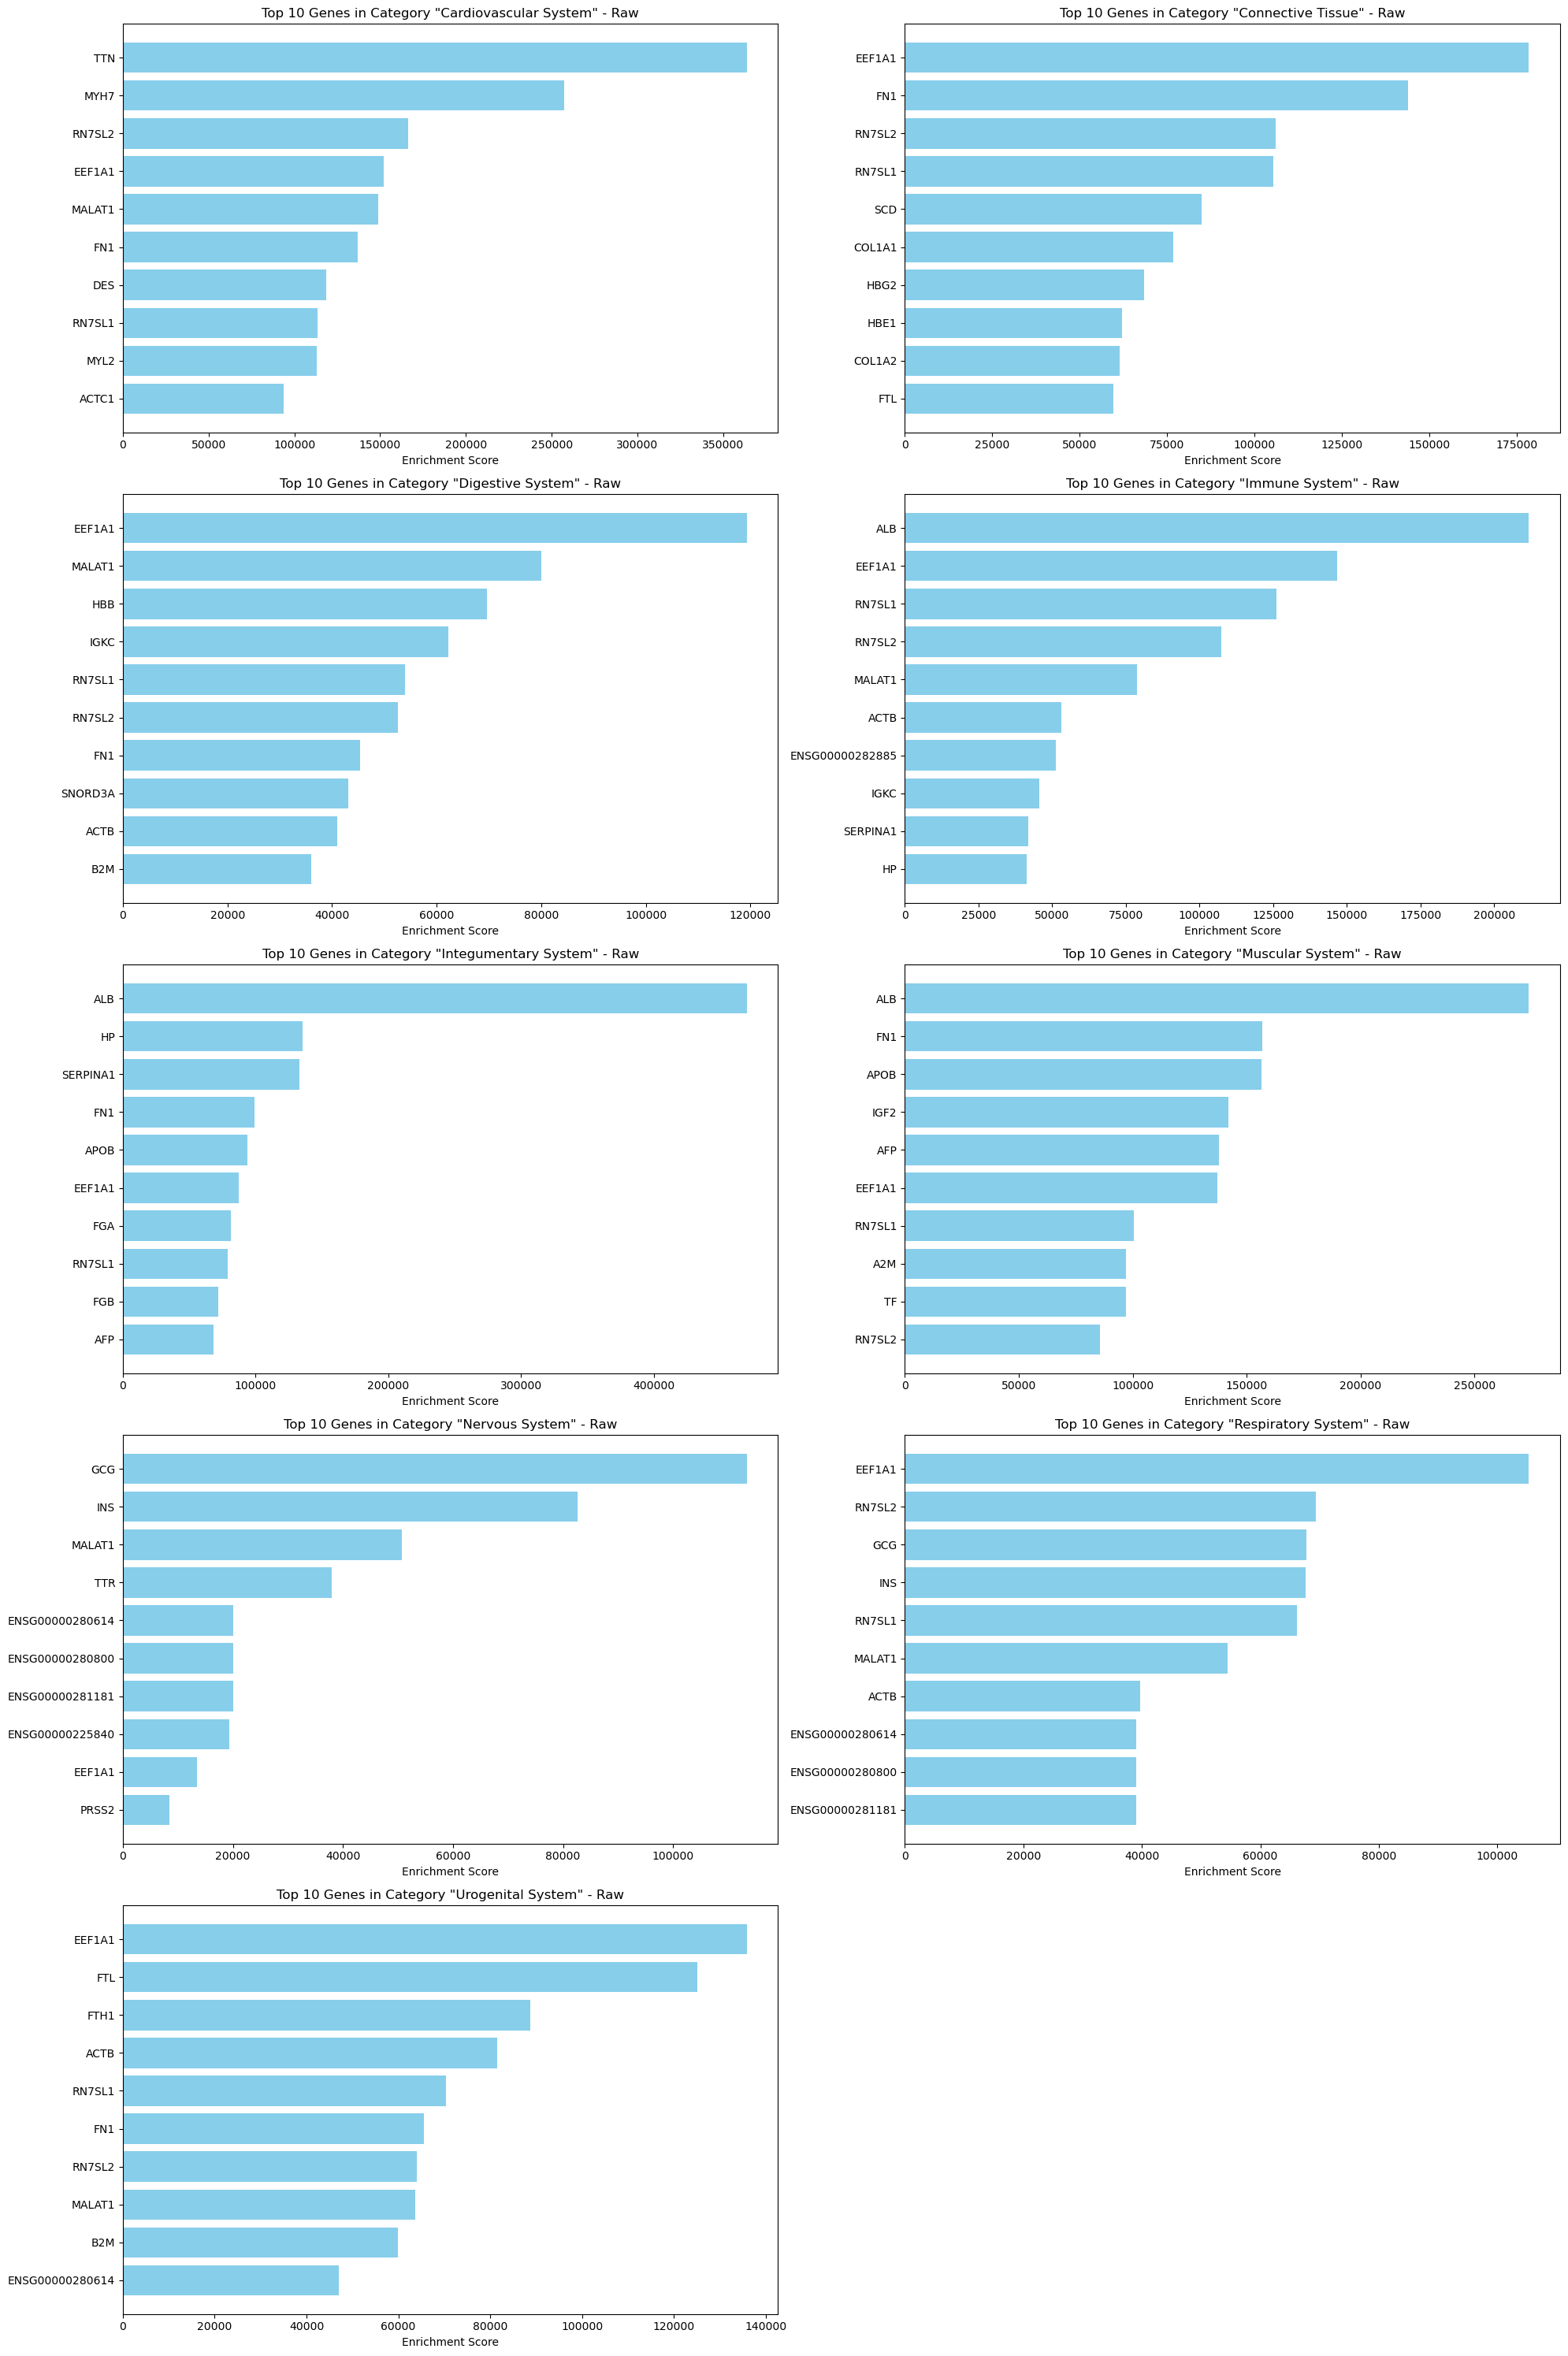

In [58]:
import matplotlib.pyplot as plt

# Set the number of columns and rows for the subplots
num_columns = 2  # Change this value to adjust the number of columns
num_rows = (len(df.columns) + num_columns - 1) // num_columns

# Create the subplots
fig, axes = plt.subplots(num_rows, num_columns, figsize=(20, 30))

# Flatten the axes array to easily access each subplot
axes = axes.flatten()

# Plot top 10 genes for each category
for i, col in enumerate(df.columns):
    top_10 = df[col].nlargest(10)
    genes = [gene_names.index(gene) for gene in top_10.index]
    scores = top_10.values

    # Plot in the respective subplot
    ax = axes[i]
    ax.barh(range(len(genes)), scores, align='center', color='skyblue')
    ax.set_yticks(range(len(genes)))
    ax.set_yticklabels([gene_names[gene] for gene in genes])
    ax.set_xlabel('Enrichment Score')
    ax.set_title('Top 10 Genes in Category "{}" - Raw'.format(col))
    ax.invert_yaxis()

# Hide any extra subplots
for j in range(len(df.columns), num_columns*num_rows):
    fig.delaxes(axes[j])

# Adjust the layout and spacing
plt.tight_layout()

# Show the plot
plt.show()


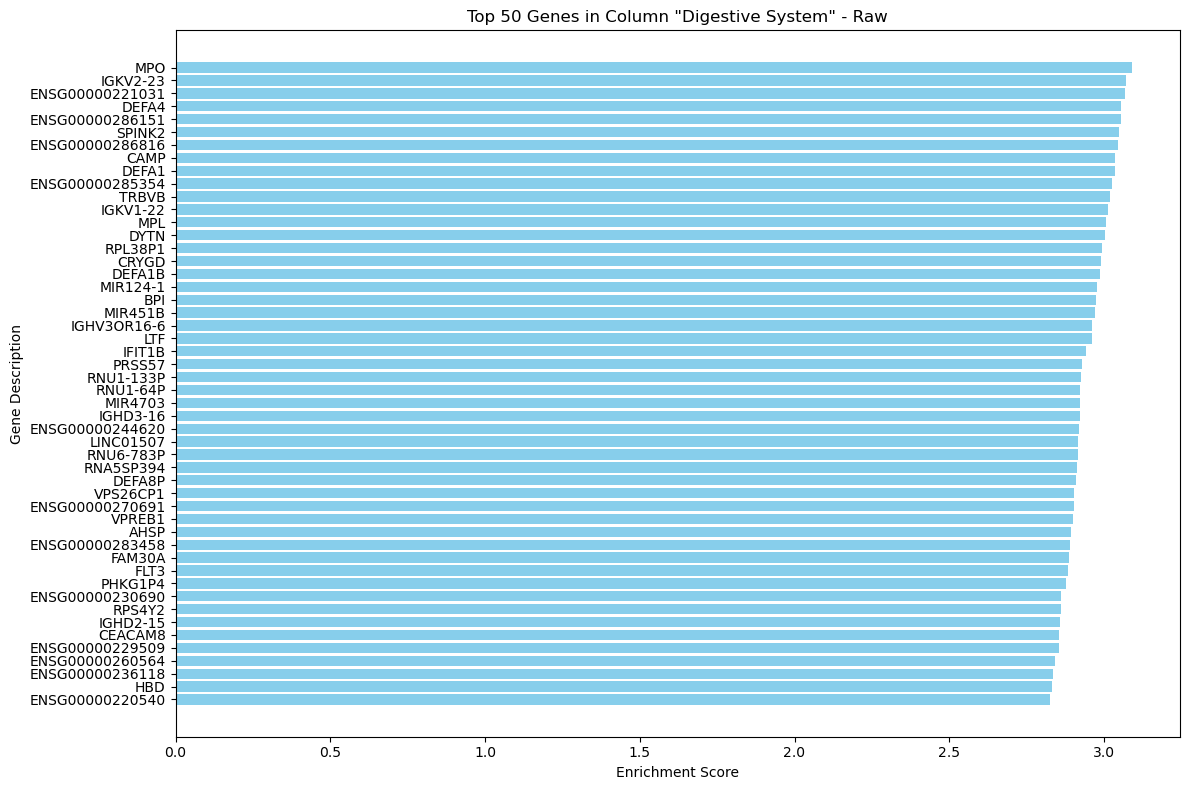

In [20]:
import matplotlib.pyplot as plt

# Select the column for the bar plot
column_name = "Digestive System"

# Get the top 50 scores for the selected column
top_50 = df[column_name].nlargest(50)
genes = [gene_names.index(gene) for gene in top_50.index]
scores = top_50.values

plt.figure(figsize=(12, 8))
plt.barh(range(len(genes)), scores, align='center', color='skyblue')
plt.yticks(range(len(genes)), [gene_names[gene] for gene in genes])
plt.xlabel('Enrichment Score')
plt.ylabel('Gene Description')
plt.title('Top 50 Genes in Column "{}" - Raw'.format(column_name))
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

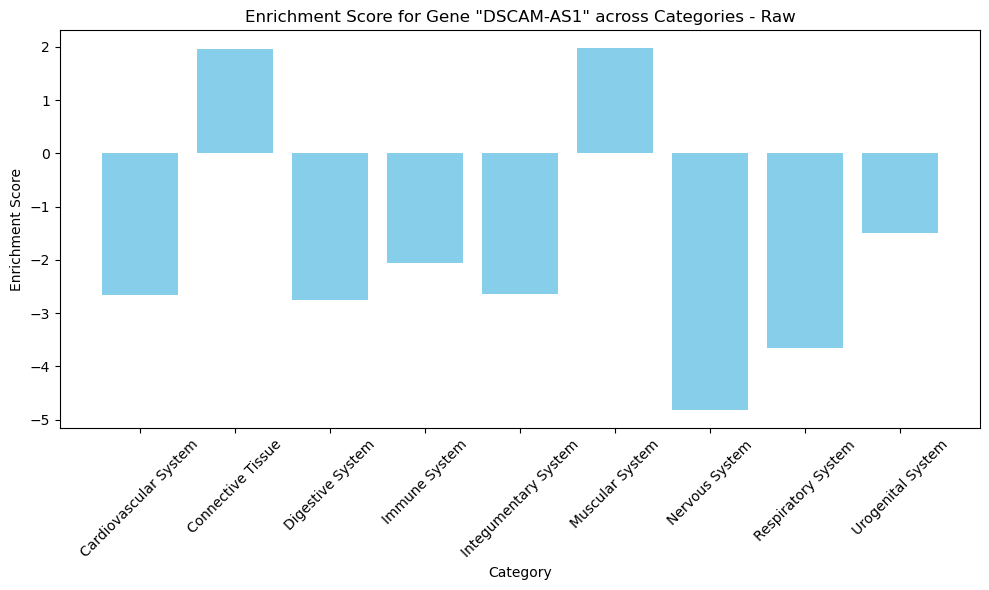

In [21]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'DSCAM-AS1'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories - Raw'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


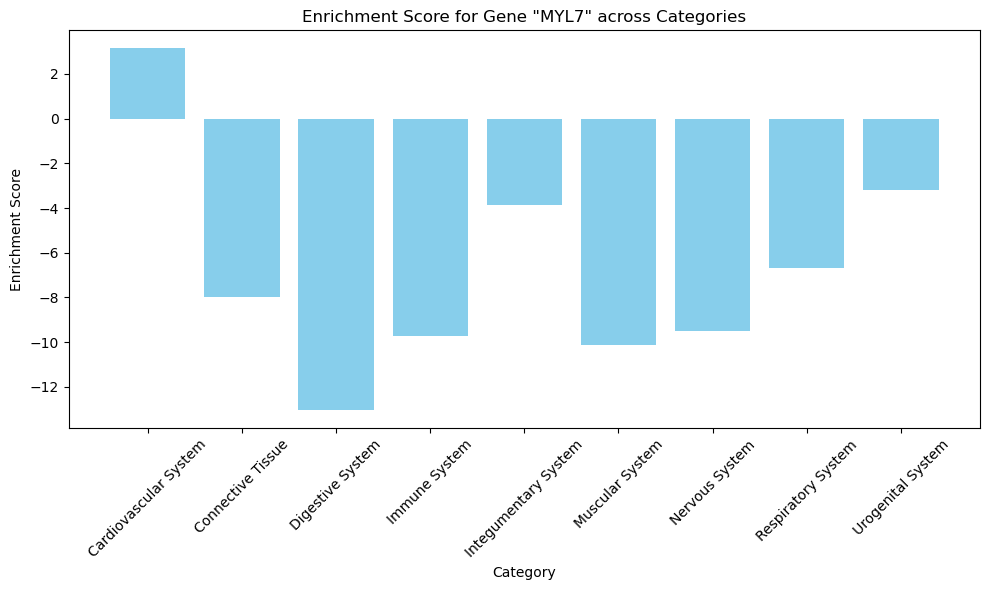

In [22]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'MYL7'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


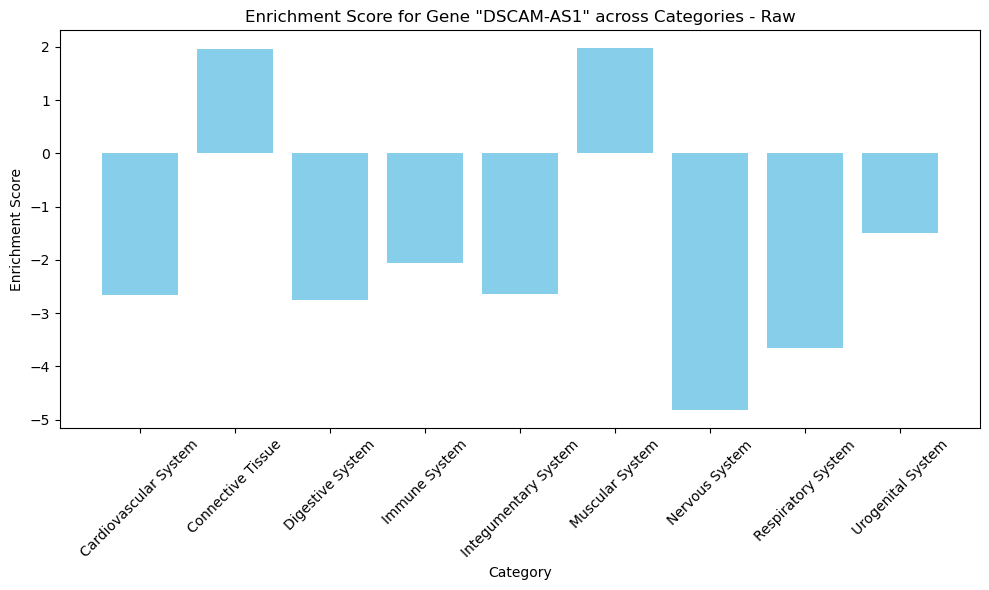

In [23]:
import matplotlib.pyplot as plt

# Select the 'high scoring' gene
gene_name = 'DSCAM-AS1'

# Calculate enrichment scores for the gene in each category
enrichment_scores = []
for col in df.columns:
    enrichment_scores.append(df.loc[gene_name, col])

# Create bar plot
plt.figure(figsize=(10, 6))
plt.bar(df.columns, enrichment_scores, color='skyblue')
plt.xlabel('Category')
plt.ylabel('Enrichment Score')
plt.title('Enrichment Score for Gene "{}" across Categories - Raw'.format(gene_name))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
